In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet

In [6]:
# 1. Load and clean data
df = pd.read_csv(r"D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\bestsellers with categories.csv")
df = df.drop_duplicates(subset="Name").reset_index(drop=True)

features = ["User Rating", "Reviews", "Price", "Year"]
X = df[features]

# 2. Scale features
X_scaled = StandardScaler().fit_transform(X)

# 3. Distances and similarities (first 5 books)
sample = X_scaled[:5]
print("Euclidean:\n", np.round(squareform(pdist(sample, "euclidean")), 2))
print("Manhattan:\n", np.round(squareform(pdist(sample, "cityblock")), 2))
print("Cosine distance:\n", np.round(squareform(pdist(sample, "cosine")), 2))
print("Cosine similarity:\n", np.round(1 - squareform(pdist(sample, "cosine")), 2))

Euclidean:
 [[0.   2.54 0.94 0.52 1.41]
 [2.54 0.   2.77 3.04 2.83]
 [0.94 2.77 0.   0.97 1.21]
 [0.52 3.04 0.97 0.   1.59]
 [1.41 2.83 1.21 1.59 0.  ]]
Manhattan:
 [[0.   4.77 1.46 0.88 2.65]
 [4.77 0.   4.83 5.65 4.84]
 [1.46 4.83 0.   1.43 2.09]
 [0.88 5.65 1.43 0.   2.92]
 [2.65 4.84 2.09 2.92 0.  ]]
Cosine distance:
 [[0.   1.92 0.17 0.01 0.33]
 [1.92 0.   1.65 1.94 1.49]
 [0.17 1.65 0.   0.17 0.22]
 [0.01 1.94 0.17 0.   0.39]
 [0.33 1.49 0.22 0.39 0.  ]]
Cosine similarity:
 [[ 1.   -0.92  0.83  0.99  0.67]
 [-0.92  1.   -0.65 -0.94 -0.49]
 [ 0.83 -0.65  1.    0.83  0.78]
 [ 0.99 -0.94  0.83  1.    0.61]
 [ 0.67 -0.49  0.78  0.61  1.  ]]


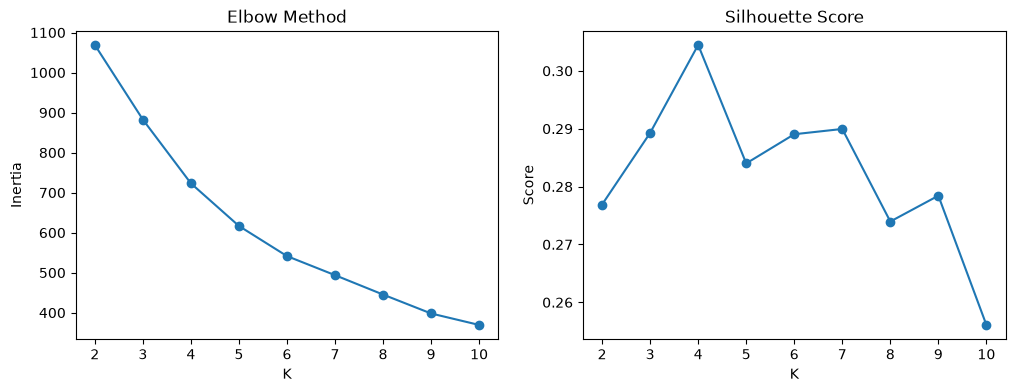

Best K by silhouette: 4


In [7]:
# 4. K-Means: elbow method and silhouette score
inertia, sil = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_range, inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")
ax[1].plot(K_range, sil, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Score")
plt.show()

best_k = K_range[int(np.argmax(sil))]
print("Best K by silhouette:", best_k)

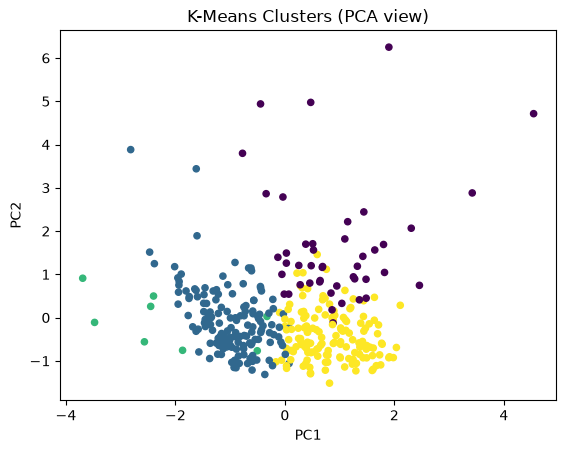

In [8]:
# 5. Final K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# 6. Plot clusters using PCA (2D view)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["KMeans_Cluster"], cmap="viridis", s=20)
plt.title("K-Means Clusters (PCA view)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()



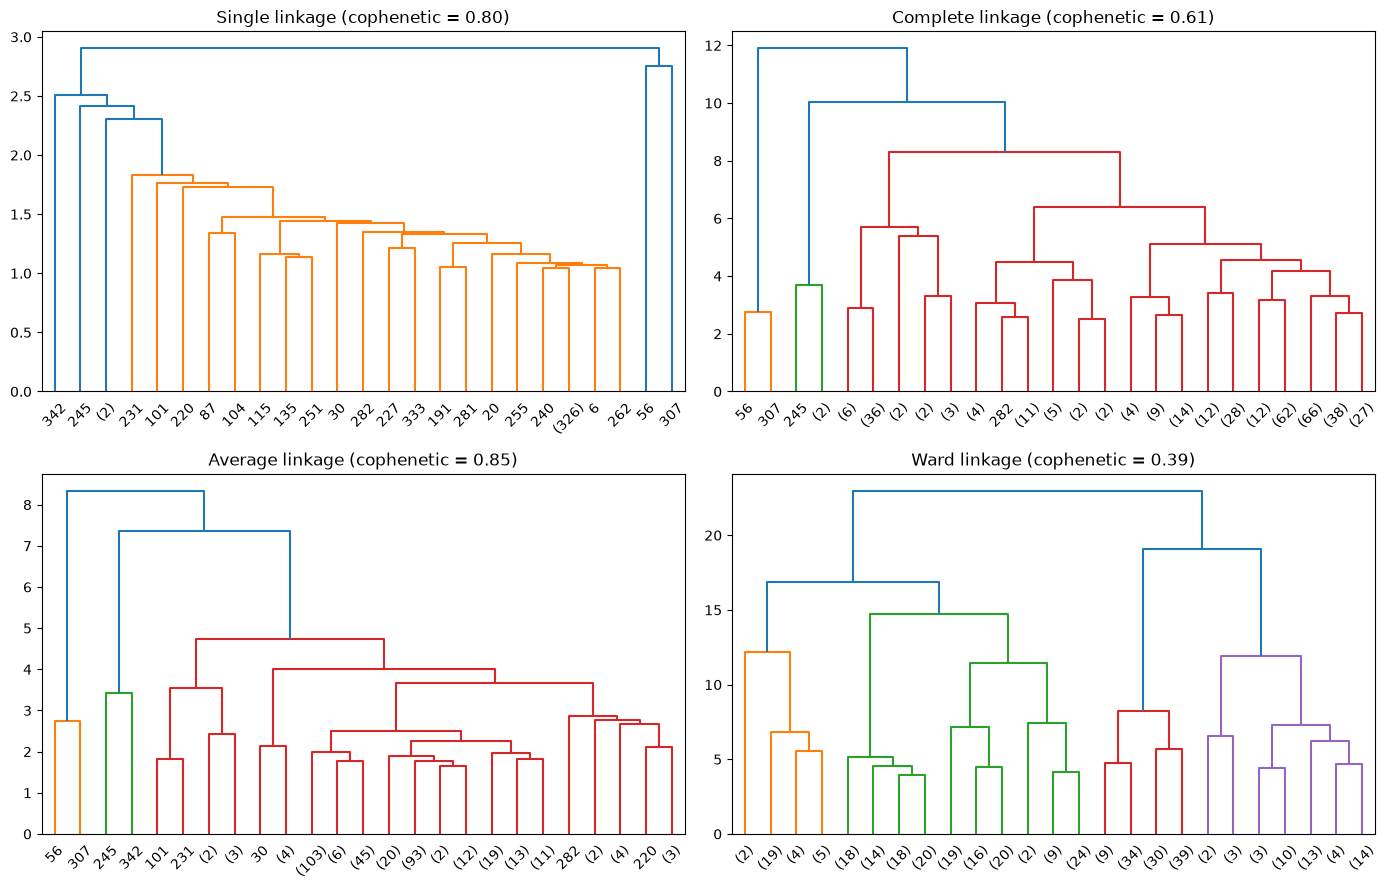

Hierarchical silhouette: 0.22404634738723697
K-Means silhouette: 0.3044758816785747

K-Means cluster profile:
                 User Rating   Reviews  Price     Year
KMeans_Cluster                                       
0                      4.55  31611.44  12.27  2014.29
1                      4.53   5153.19  13.52  2010.63
2                      4.66   5535.75  59.25  2011.38
3                      4.71   8127.60  10.35  2016.36

K-Means vs Genre:
 Genre           Fiction  Non Fiction
KMeans_Cluster                      
0                    35           10
1                    64           87
2                     3            5
3                    58           89

K-Means vs Hierarchical:
 HC_Cluster        0   1    2   3
KMeans_Cluster                  
0                 1   2    1  41
1               126  18    7   0
2                 0   8    0   0
3                33   2  104   8


In [9]:
# 7. Dendrograms with different linkage methods
methods = ["single", "complete", "average", "ward"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, method in zip(axes.ravel(), methods):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, truncate_mode="lastp", p=25, ax=ax)
    c, _ = cophenet(Z, pdist(X_scaled))
    ax.set_title(f"{method.capitalize()} linkage (cophenetic = {c:.2f})")
plt.tight_layout()
plt.show()

# 8. Hierarchical clustering (Ward) with same number of clusters
hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
df["HC_Cluster"] = hc.fit_predict(X_scaled)
print("Hierarchical silhouette:", silhouette_score(X_scaled, df["HC_Cluster"]))
print("K-Means silhouette:", silhouette_score(X_scaled, df["KMeans_Cluster"]))

# 9. Analyse clusters
print("\nK-Means cluster profile:\n", df.groupby("KMeans_Cluster")[features].mean().round(2))
print("\nK-Means vs Genre:\n", pd.crosstab(df["KMeans_Cluster"], df["Genre"]))
print("\nK-Means vs Hierarchical:\n", pd.crosstab(df["KMeans_Cluster"], df["HC_Cluster"]))